# **Adult Census Income Prediction Using Machine Learning**

## Project Overview

This project compares several Machine Learning algorithms for predicting whether an individual's annual income exceeds **$50,000** using the **Adult Census Income Dataset**.

The notebook follows a complete machine learning workflow including:

- Data Loading
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Feature Engineering
- Data Preprocessing
- Model Training
- Model Evaluation
- Performance Comparison
- Feature Importance Analysis
- Best Model Selection

## Dataset

Dataset: Adult Census Income Dataset

Target Variable:

- " <=50K → 0 "
- " >50K → 1 "

## Machine Learning Algorithms

- Logistic Regression
- Support Vector Machine (SVM)
- Naive Bayes
- Decision Tree
- Random Forest
- Linear Regression (classification adaptation)
- K-Means Clustering (unsupervised)

---

In [3]:
# IMPORT REQUIRED LIBRARIES
"""
Import all libraries required for data manipulation, visualization,
preprocessing, machine learning, and evaluation.
"""

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    adjusted_rand_score,
    normalized_mutual_info_score )

# Utilities
import time
import warnings
warnings.filterwarnings("ignore")

# Plot Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["font.size"] = 12

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# LOAD "ADULT CENSUS INCOME DATASET"
"""
Read the dataset and display the first few records.
"""

# Load dataset
data = pd.read_csv("adult-census-income.csv")

print("Dataset Loaded Successfully!")
print("\nDataset Shape:", data.shape)
display(data.head())

Dataset Loaded Successfully!

Dataset Shape: (11804, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K


In [5]:
# DATASET OVERVIEW
"""
Display basic information including:
• Number of rows
• Number of columns
• Data types
• Statistical summary
"""

print("Rows :", data.shape[0])
print("Columns :", data.shape[1])

print("\nColumn Names\n")
display(pd.DataFrame(data.columns, columns=["Features"]))
print("\nDataset Information\n")
data.info()
print("\nStatistical Summary\n")
display(data.describe())

Rows : 11804
Columns : 15

Column Names



,Features
0,age
1,workclass
2,fnlwgt
3,education
4,education_num
5,marital_status
6,occupation
7,relationship
8,race
9,sex



Dataset Information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11804 entries, 0 to 11803
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             11804 non-null  int64  
 1   workclass       11804 non-null  object 
 2   fnlwgt          11804 non-null  int64  
 3   education       11804 non-null  object 
 4   education_num   11804 non-null  int64  
 5   marital_status  11804 non-null  object 
 6   occupation      11804 non-null  object 
 7   relationship    11804 non-null  object 
 8   race            11803 non-null  object 
 9   sex             11803 non-null  object 
 10  capital_gain    11803 non-null  float64
 11  capital_loss    11803 non-null  float64
 12  hours_per_week  11803 non-null  float64
 13  native_country  11803 non-null  object 
 14  income          11803 non-null  object 
dtypes: float64(3), int64(3), object(9)
memory usage: 1.4+ MB

Statistical Summary



,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,11804.000000,1.180400e+04,11804.000000,11803.000000,11803.000000,11803.000000
mean,38.460437,1.902684e+05,10.075313,1042.517750,89.371855,40.509023
std,13.636195,1.048778e+05,2.546826,7179.274023,404.470637,12.319312
min,17.000000,1.921400e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.184582e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.791260e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.389478e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.226583e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
# INSPECT MISSING VALUES AND DUPLICATE RECORDS
"""
Check whether the dataset contains:
• Missing values
• Duplicate rows
These issues should be handled before training machine learning models.
"""

# Replace '?' with NaN
data.replace("?", np.nan, inplace=True)

# Remove leading/trailing spaces from object columns
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

print("Missing Values")
display(data.isnull().sum())
print("\nDuplicate Records:", data.duplicated().sum())

Missing Values


,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,1
sex,1



Duplicate Records: 4


In [7]:
# HANDLE MISSING VALUES AND DUPLICATES
"""
Remove duplicate records while preserving all missing values for preprocessing.
Missing values will later be handled using SimpleImputer within the preprocessing pipeline.
"""

# Remove duplicate rows
data = data.drop_duplicates()

print("Dataset Shape After Removing Duplicates")
print(data.shape)

Dataset Shape After Removing Duplicates
(11800, 15)


In [8]:
# CREATE BINARY TARGET VARIABLE
"""
Convert income into binary labels.
• <=50K  → 0
• >50K   → 1
"""

data["income_bin"] = (
    data["income"] == ">50K"
).astype(int)

display(
    data[["income", "income_bin"]].head()
)

,income,income_bin
0,<=50K,0
1,<=50K,0
2,<=50K,0
3,<=50K,0
4,<=50K,0


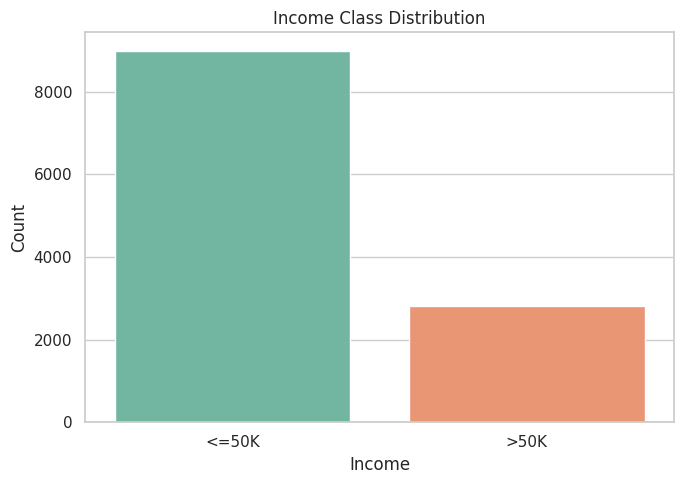

In [9]:
# INCOME CLASS DISTRIBUTION
"""
Visualize the number of samples belonging to each income class.
"""

plt.figure(figsize=(7,5))

sns.countplot(
    data=data,
    x="income",
    palette="Set2"
)

plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [10]:
# CLASS DISTRIBUTION PERCENTAGE
"""
Display the percentage of samples belonging to each target class.
"""

class_distribution = (
    data["income"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    class_distribution.to_frame(
        name="Percentage (%)"
    )
)

,Percentage (%)
income,
<=50K,76.16
>50K,23.84


In [11]:
# EXPLORE NUMERICAL FEATURES
"""
Display summary statistics for all numerical features in the dataset.
"""

numeric_features = data.select_dtypes(
    include=["int64","float64"]
)

display(numeric_features.describe())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,income_bin
count,11800.000000,1.180000e+04,11800.000000,11799.000000,11799.000000,11799.000000,11800.000000
mean,38.460254,1.902720e+05,10.075085,1042.871176,89.402153,40.514705,0.238390
std,13.627680,1.048781e+05,2.547115,7180.465285,404.535849,12.314889,0.426117
min,17.000000,1.921400e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.184710e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.791260e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,47.000000,2.389238e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.226583e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


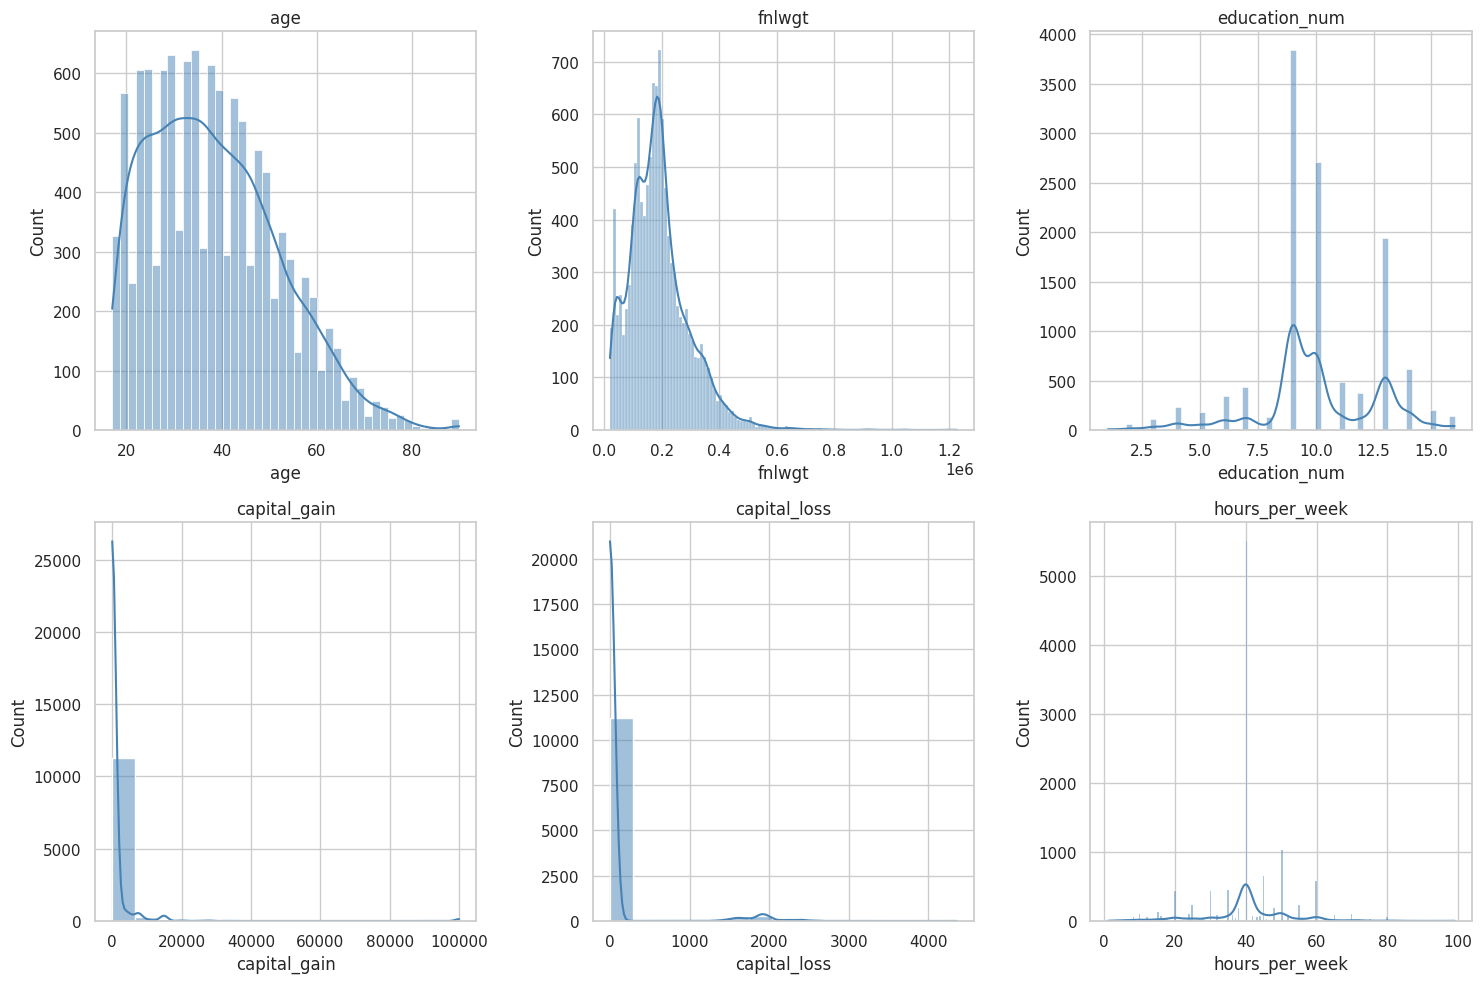

In [12]:
# DISTRIBUTION OF NUMERICAL FEATURES
"""
Plot histograms to understand the distribution of each numerical feature.
"""

numeric_cols = numeric_features.columns

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15,10)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):

    sns.histplot(
        data[col],
        kde=True,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()

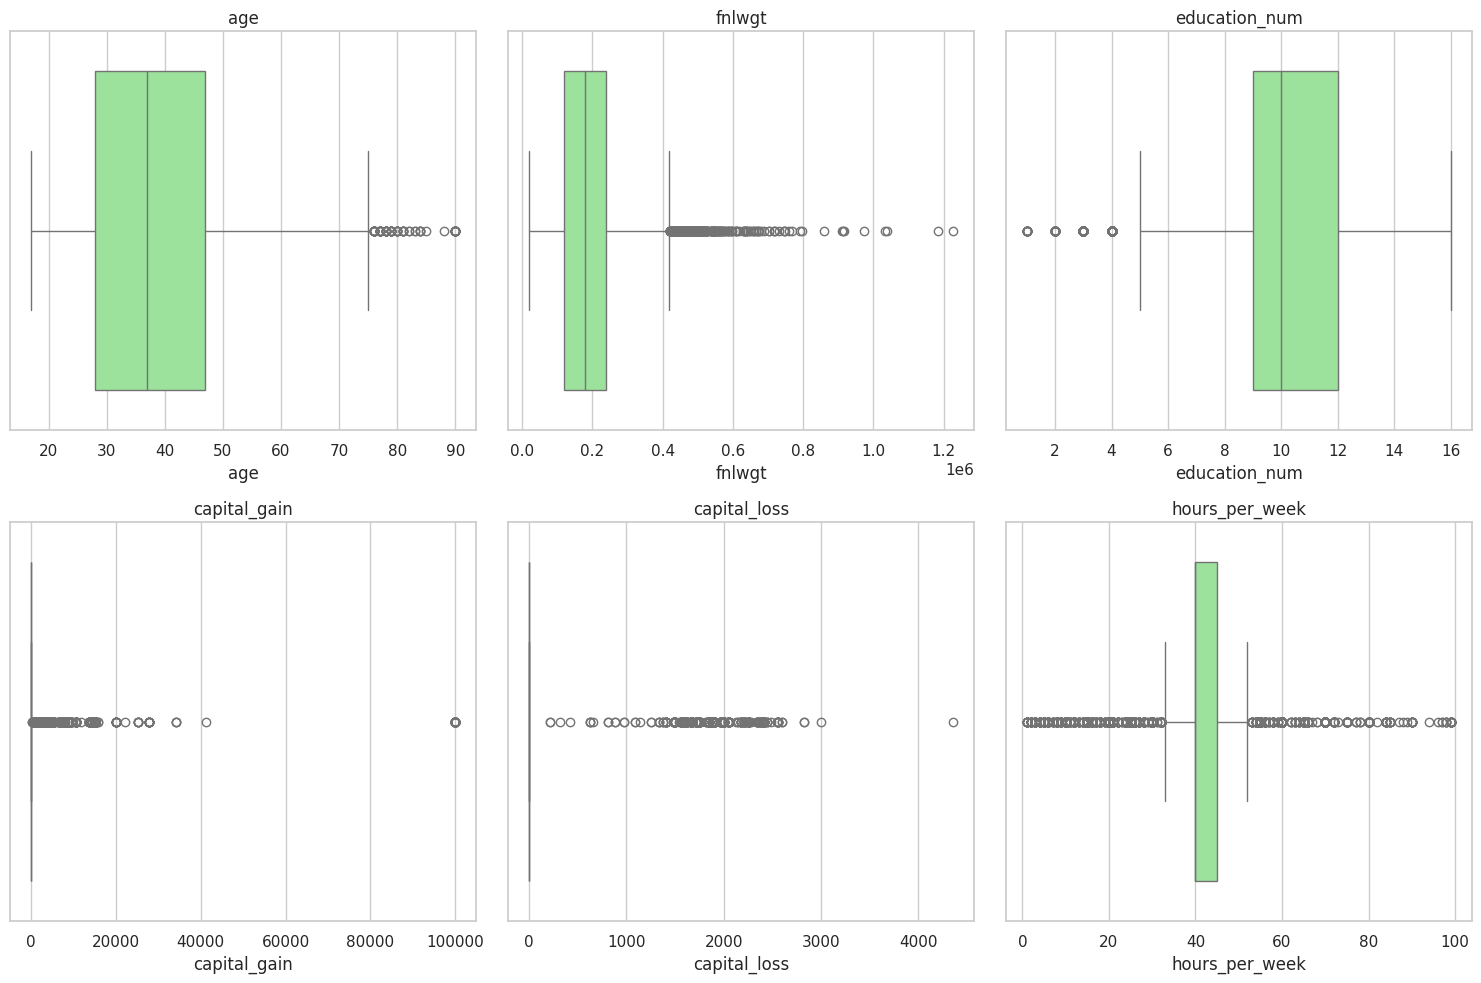

In [13]:
# BOXPLOTS FOR OUTLIER DETECTION
"""
Visualize possible outliers present in the numerical features.
"""

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15,10)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):

    sns.boxplot(
        x=data[col],
        ax=ax,
        color="lightgreen"
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()

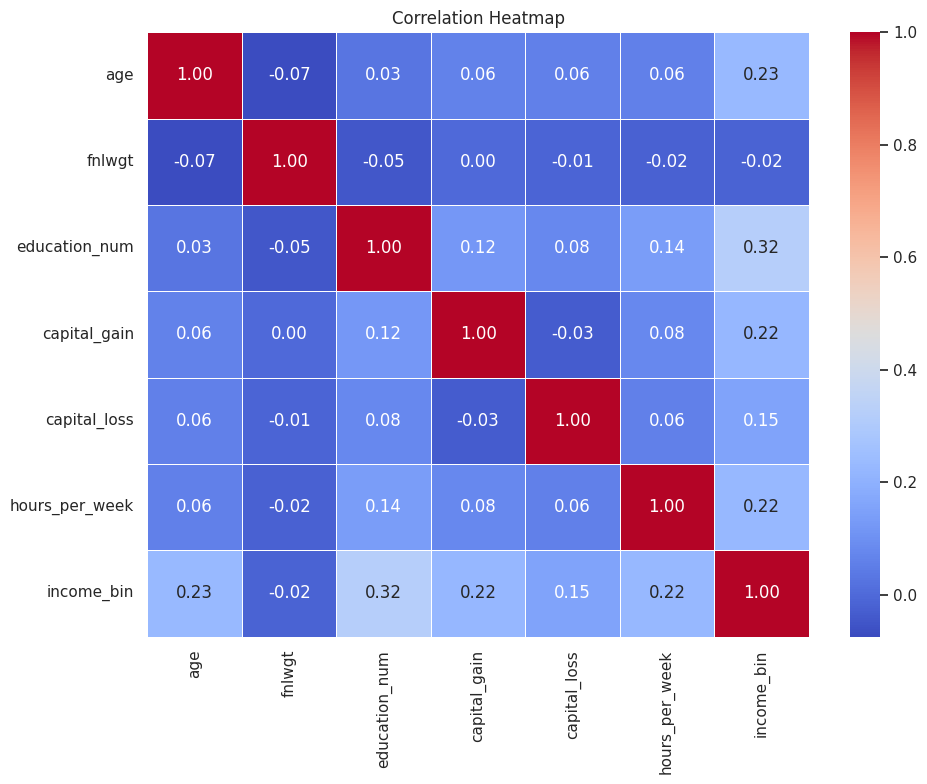

In [14]:
# CORELATION ANALYSIS
"""
Compute and visualize the correlation matrix for numerical
features to identify relationships between variables.
"""

plt.figure(figsize=(10, 8))

corr_matrix = numeric_features.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [15]:
# CATEGORICAL FEATURE SUMMARY
"""
Display the number of unique categories present in each categorical feature.
"""

categorical_cols = data.select_dtypes(include="object").columns.tolist()

summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique Values": [data[col].nunique() for col in categorical_cols]
})

display(summary)

,Feature,Unique Values
0,workclass,9
1,education,16
2,marital_status,7
3,occupation,15
4,relationship,7
5,race,5
6,sex,2
7,native_country,41
8,income,2


In [16]:
# SEPARATE FEATURES AND TARGET VARIABLE
"""
Split the dataset into:
• X → Input Features
• y → Target Variable
"""

# Drop original income column and binary target from features
X = data.drop(columns=["income", "income_bin"])

# Binary target
y = data["income_bin"]

print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape  :", y.shape)

Feature Matrix Shape : (11800, 14)
Target Vector Shape  : (11800,)


In [17]:
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
"""
Separate feature columns according to their data types for preprocessing.
"""

numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Features :", len(numeric_cols))
print("Categorical Features :", len(categorical_cols))

print("\nNumerical Columns")
print(numeric_cols)

print("\nCategorical Columns")
print(categorical_cols)

Numerical Features : 6
Categorical Features : 8

Numerical Columns
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Columns
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [18]:
# CREATE DATA PREPROCESSING PIPELINE
"""
Numerical Features: • Median Imputation • Standard Scaling
Categorical Features: • Most Frequent Imputation • One-Hot Encoding
Combine both transformations using ColumnTransformer.
"""

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [19]:
# SPLIT DATASET AND APPLY PREPROCESSING
"""
Split the dataset into: • 80% Training Data • 20% Testing Data
Then fit the preprocessing pipeline on the training data and transform both datasets.
"""

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Apply preprocessing
X_train_proc = preprocessor.fit_transform(X_train)

X_test_proc = preprocessor.transform(X_test)

print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

print("\nProcessed Training Shape :", X_train_proc.shape)
print("Processed Testing Shape  :", X_test_proc.shape)

Training Samples : 9440
Testing Samples  : 2360

Processed Training Shape : (9440, 108)
Processed Testing Shape  : (2360, 108)


In [20]:
# CREATE MACHINE LEARNING MODELS
"""
Initialize all supervised learning models that will be compared in this project.
"""

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine": SVC( probability=True, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier( random_state=42    ),
    "Random Forest": RandomForestClassifier( n_estimators=200, random_state=42),
    "Linear Regression": LinearRegression()
}

print("Models initialized successfully.")

Models initialized successfully.


In [21]:
# CREATE EVALUATION FUNCTION
"""
This function trains a model, makes predictions, calculates evaluation metrics,
and stores the results for later comparison.
"""

results = {}
trained_models = {}
predictions = {}
probabilities = {}
training_times = {}


def evaluate_model(name, model):
    start_time = time.time()

    # GaussianNB requires dense matrices
    if name == "Naive Bayes":
        X_train_used = X_train_proc.toarray()
        X_test_used = X_test_proc.toarray()
    else:
        X_train_used = X_train_proc
        X_test_used = X_test_proc

    model.fit(X_train_used, y_train)
    end_time = time.time()
    training_times[name] = end_time - start_time

    # Predictions
    if name == "Linear Regression":
        y_pred = model.predict(X_test_used)
        y_pred = (y_pred >= 0.5).astype(int)
    else:
        y_pred = model.predict(X_test_used)

    predictions[name] = y_pred
    trained_models[name] = model

    # Probabilities
    if hasattr(model, "predict_proba"):
        probabilities[name] = model.predict_proba(X_test_used)[:,1]
    elif hasattr(model, "decision_function"):
        probabilities[name] = model.decision_function(X_test_used)
    else:
        probabilities[name] = None

    # Evaluation Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (s)": training_times[name]
    }

In [22]:
# TRAIN ALL SUPERVISED LEARNING MODELS
"""
Iterate through every machine learning model, train it,
evaluate its performance, and save the evaluation metrics.
"""

for name, model in models.items():
    print(f"Training: {name}")
    evaluate_model(name, model)

print("\nAll supervised models trained successfully.")

Training: Logistic Regression
Training: Support Vector Machine
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest
Training: Linear Regression

All supervised models trained successfully.


In [23]:
# DISPLAY MODEL PERFORMANCE SUMMARY
"""
Convert the evaluation results into a DataFrame for easier comparison.
"""

comparison = pd.DataFrame(results).T
comparison = comparison.sort_values(by="F1 Score", ascending=False)

display(
    comparison.style
        .background_gradient(
            cmap="Greens",
            subset=["Accuracy","Precision","Recall","F1 Score"]
        )
        .format("{:.4f}")
)

,Accuracy,Precision,Recall,F1 Score,Training Time (s)
Random Forest,0.8619,0.7604,0.6146,0.6798,15.1859
Logistic Regression,0.8606,0.7671,0.5968,0.6713,0.2934
Support Vector Machine,0.8597,0.7900,0.5613,0.6563,21.2680
Decision Tree,0.8199,0.6255,0.6110,0.6181,0.3615
Linear Regression,0.8475,0.7925,0.4885,0.6044,0.0746
Naive Bayes,0.4178,0.2869,0.9698,0.4428,0.0259


In [24]:
# CLASSIFICATION REPORTS
"""
Display detailed evaluation metrics for each supervised learning model.
"""

for name in models.keys():
    print("="*60)
    print(name)
    print("="*60)
    print(
        classification_report(
            y_test,
            predictions[name]
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      1797
           1       0.77      0.60      0.67       563

    accuracy                           0.86      2360
   macro avg       0.82      0.77      0.79      2360
weighted avg       0.85      0.86      0.85      2360

Support Vector Machine
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      1797
           1       0.79      0.56      0.66       563

    accuracy                           0.86      2360
   macro avg       0.83      0.76      0.78      2360
weighted avg       0.85      0.86      0.85      2360

Naive Bayes
              precision    recall  f1-score   support

           0       0.96      0.24      0.39      1797
           1       0.29      0.97      0.44       563

    accuracy                           0.42      2360
   macro avg       0.62      0.61      0.42      2360
weighted avg       

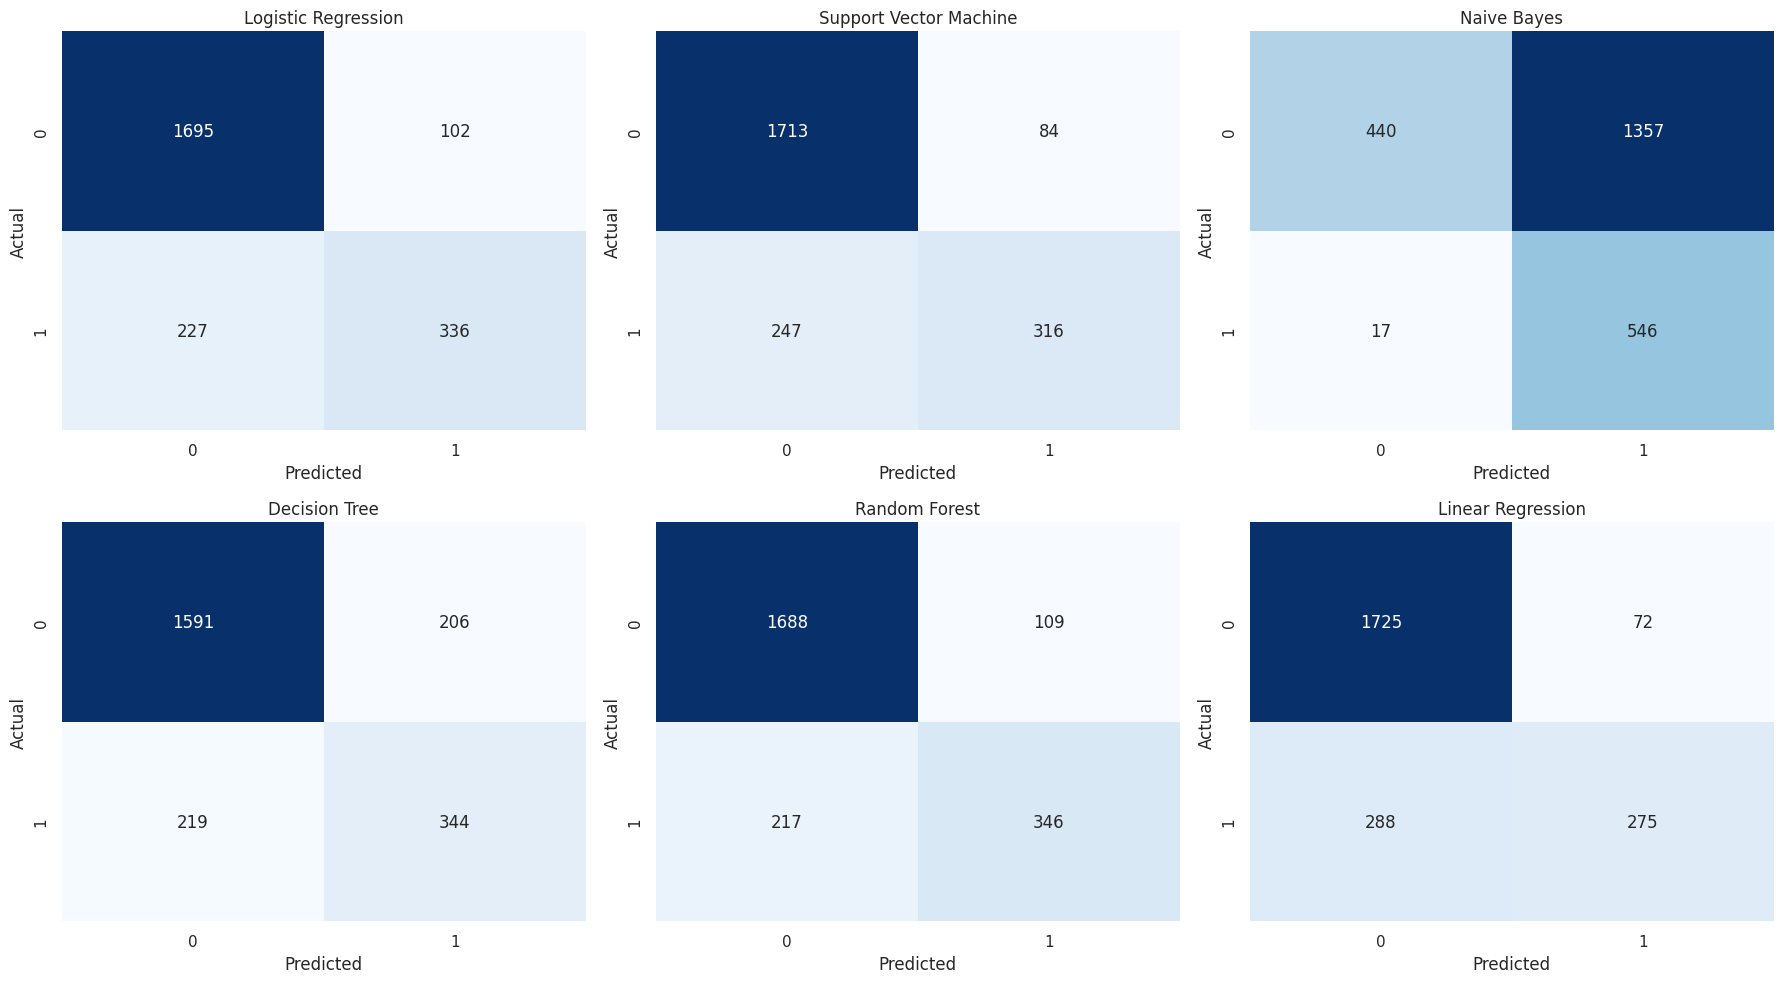

In [25]:
# CONFUSION MATRICES
"""
Display confusion matrices for all supervised learning models using a 2 × 3 layout.
"""

fig, axes = plt.subplots(2, 3, figsize=(18,10))

axes = axes.flatten()

for ax, name in zip(axes, models.keys()):
    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

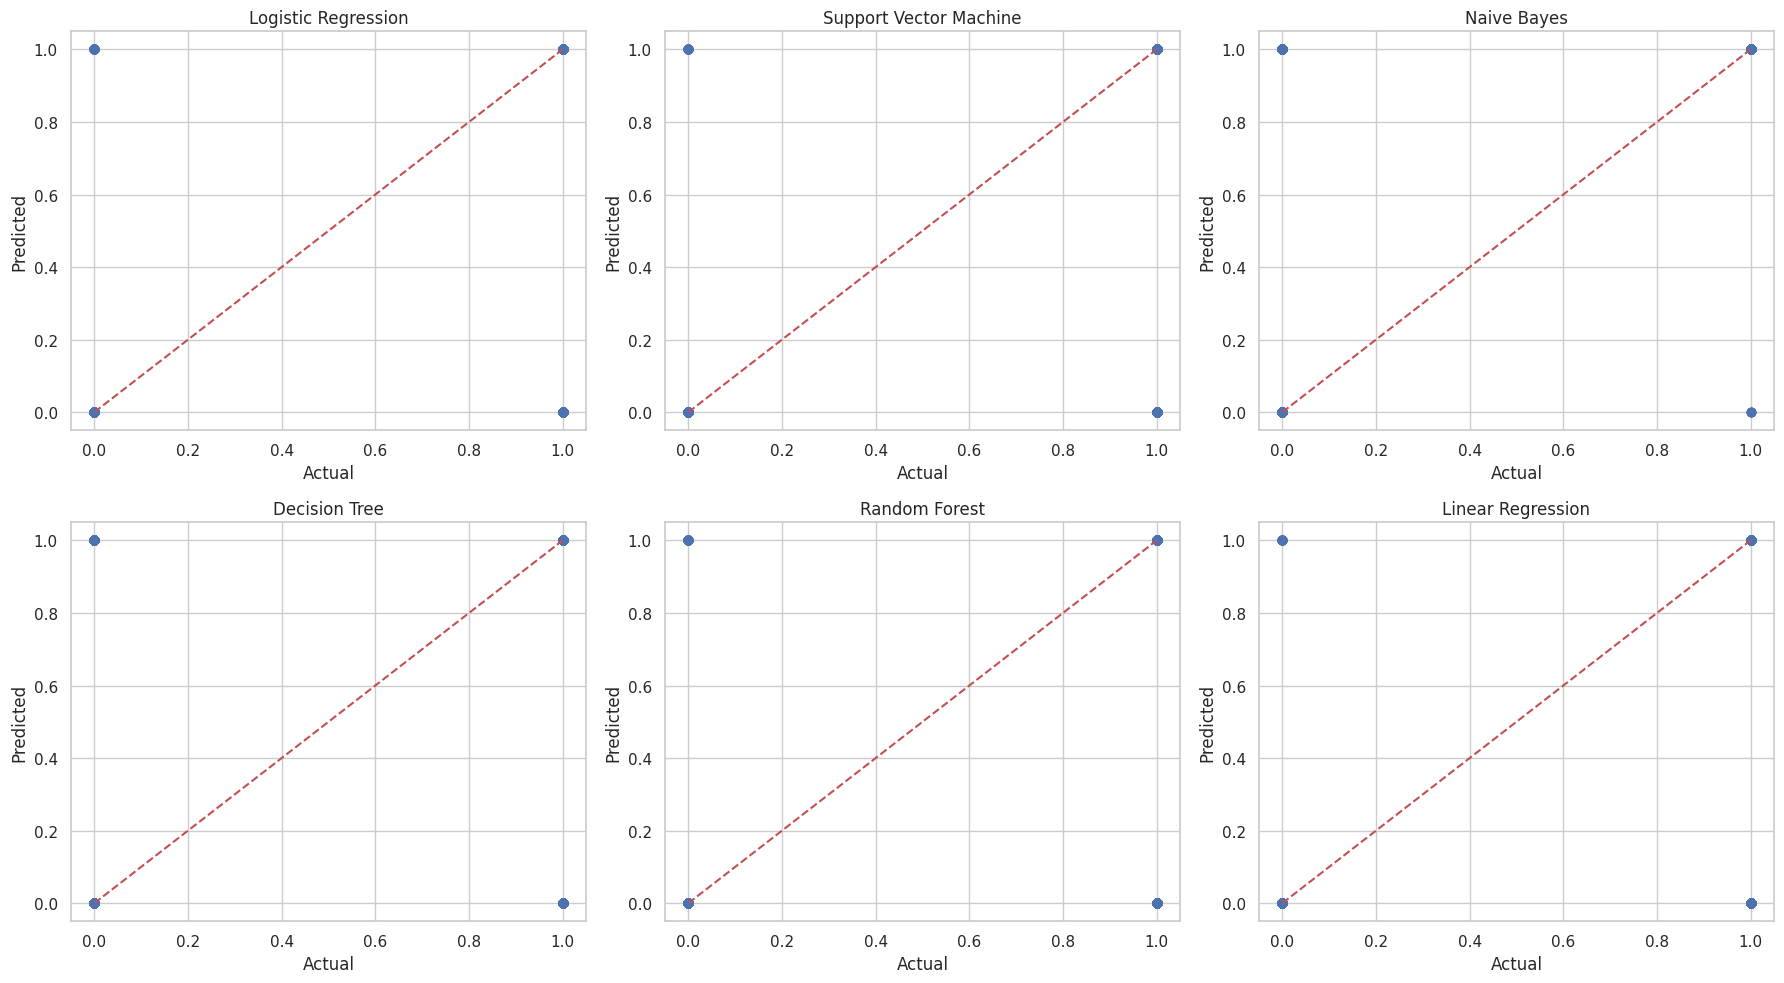

In [26]:
# ACTUAL VS PREDICTED COMPARISON
"""
Visualize the relationship between actual labels and predicted labels for each model.
"""

fig, axes = plt.subplots(2, 3, figsize=(18,10))

axes = axes.flatten()

for ax, name in zip(axes, models.keys()):
    ax.scatter(
        y_test,
        predictions[name],
        alpha=0.3
    )

    ax.plot(
        [0,1],
        [0,1],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.tight_layout()
plt.show()

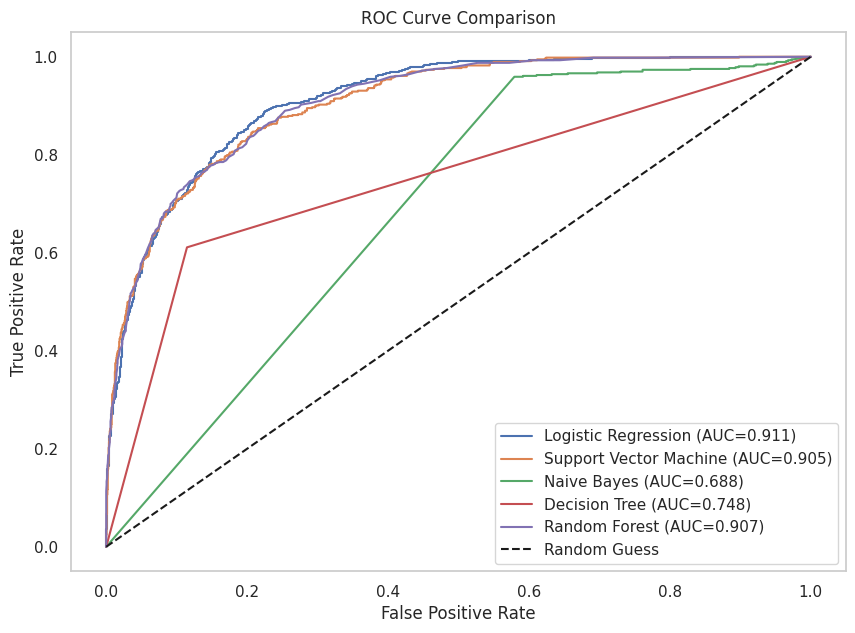

In [27]:
# ROC CURVE COMPARISON
"""
ROC curves show the trade-off between:
• True Positive Rate
• False Positive Rate
AUC score measures overall classification ability.
"""

plt.figure(figsize=(10,7))

for name in models.keys():
    if probabilities[name] is not None:
        auc_score = roc_auc_score(
            y_test,
            probabilities[name]
        )

        fpr, tpr, _ = roc_curve(
            y_test,
            probabilities[name]
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc_score:.3f})"
        )

plt.plot(
    [0,1],
    [0,1],
    "k--",
    label="Random Guess"
)

plt.title( "ROC Curve Comparison" )
plt.xlabel( "False Positive Rate" )
plt.ylabel( "True Positive Rate" )

plt.legend()
plt.grid()
plt.show()

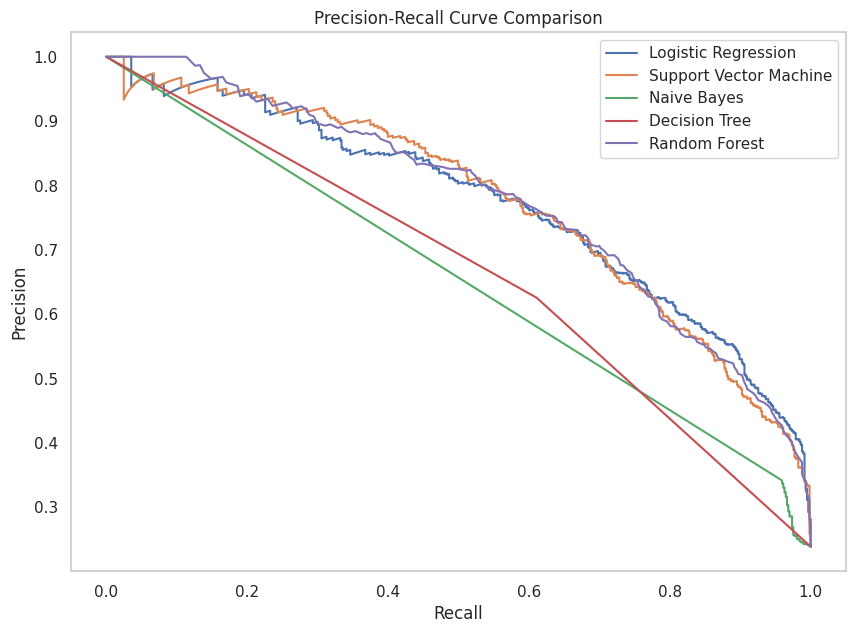

In [28]:
# PRECISION-RECALL CURVE COMPARISON
"""
Precision-Recall curves are useful when dealing with imbalanced datasets.
They show the relationship between:
• Precision
• Recall
"""

plt.figure(figsize=(10,7))

for name in models.keys():
    if probabilities[name] is not None:
        precision, recall, _ = precision_recall_curve(
            y_test,
            probabilities[name]
        )

        plt.plot(
            recall,
            precision,
            label=name
        )

plt.title( "Precision-Recall Curve Comparison" )
plt.xlabel( "Recall" )
plt.ylabel( "Precision" )

plt.legend()
plt.grid()
plt.show()

In [29]:
# RANDOM FOREST FEATURE IMPORTANCE
"""
Identify the most important features that contribute to income prediction.
Only the top 15 features are displayed for better readability.
"""

# Extract feature names after encoding
feature_names = (
    preprocessor
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance":
        trained_models["Random Forest"]
        .feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance.head(15)
display(top_features)

,Feature,Importance
1,num__fnlwgt,0.145610
0,num__age,0.143724
3,num__capital_gain,0.088129
5,num__hours_per_week,0.081140
33,cat__marital_status_Married-civ-spouse,0.063717
2,num__education_num,0.062194
54,cat__relationship_Husband,0.044173
4,num__capital_loss,0.026320
42,cat__occupation_Exec-managerial,0.022759
35,cat__marital_status_Never-married,0.022361


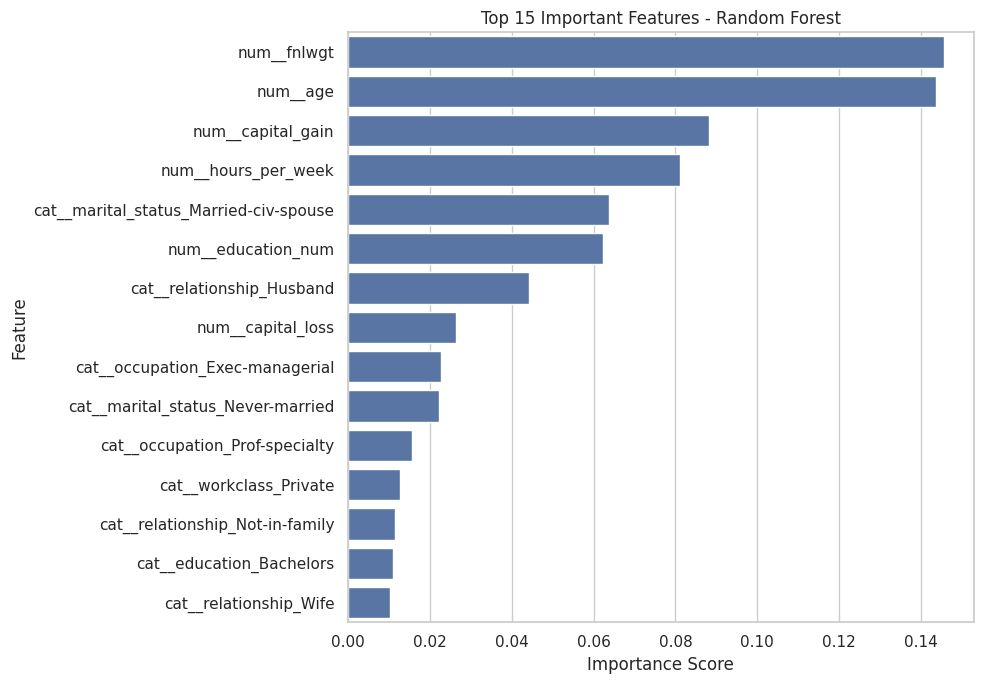

In [30]:
# VISUALIZE FEATURE IMPORTANCE
"""
Display the top 15 most influential features using Random Forest.
"""

plt.figure(figsize=(10,7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title( "Top 15 Important Features - Random Forest" )
plt.xlabel( "Importance Score" )
plt.ylabel( "Feature" )

plt.tight_layout()
plt.show()

In [31]:
# K-MEANS CLUSTERING
"""
Perform unsupervised learning using K-Means.
The algorithm groups observations without using income labels.
Number of clusters: • 0 → Lower income group  • 1 → Higher income group
"""

# Convert sparse matrix if required
if hasattr(X_train_proc, "toarray"):
    X_cluster = X_train_proc.toarray()
else:
    X_cluster = X_train_proc

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(
    X_cluster
)

print( "K-Means clustering completed successfully." )

K-Means clustering completed successfully.


In [32]:
# EVALUATE K-MEANS CLUSTERING
"""
Since K-Means does not use target labels, evaluation is performed using:
• Adjusted Rand Index (ARI)
• Normalized Mutual Information (NMI)
"""

ari = adjusted_rand_score(
    y_train,
    cluster_labels
)

nmi = normalized_mutual_info_score(
    y_train,
    cluster_labels
)

print( "Adjusted Rand Index:" )
print( "ARI = ", round(ari,4) )
print( "\nNormalized Mutual Information:" )
print( "NMI = ", round(nmi,4) )

Adjusted Rand Index:
ARI =  0.1255

Normalized Mutual Information:
NMI =  0.1725


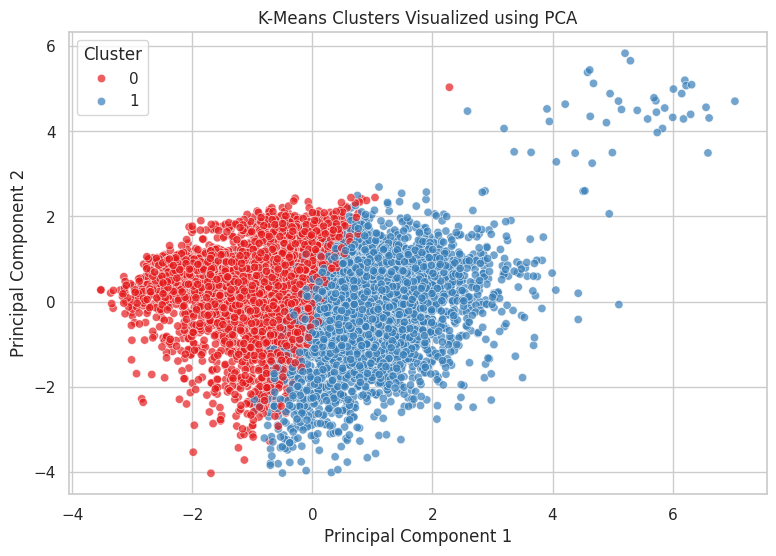

In [33]:
# PCA VISUALIZATION OF K-MEAN CLUSTERS
"""
Reduce high-dimensional encoded features into two principal components for visualization.
"""

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_cluster
)

pca_df = pd.DataFrame({
    "Component 1": X_pca[:,0],
    "Component 2": X_pca[:,1],
    "Cluster": cluster_labels
})

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=pca_df,
    x="Component 1",
    y="Component 2",
    hue="Cluster",
    palette="Set1",
    alpha=0.7
)

plt.title( "K-Means Clusters Visualized using PCA" )
plt.xlabel( "Principal Component 1" )
plt.ylabel( "Principal Component 2" )
plt.legend( title="Cluster" )
plt.show()

In [34]:
# FINAL MODEL COMPARISON
"""
Create a final ranking table based on F1 Score.
The model with the highest F1 Score will be considered the best performing classifier.
"""

final_comparison = comparison.copy()

final_comparison["Rank"] = (
    final_comparison["F1 Score"]
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
)

final_comparison = final_comparison.sort_values(
    by="Rank"
)

display(
    final_comparison.style
    .background_gradient(
        cmap="Greens",
        subset=[
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    )
    .format("{:.4f}")
)

,Accuracy,Precision,Recall,F1 Score,Training Time (s),Rank
Random Forest,0.8619,0.7604,0.6146,0.6798,15.1859,1.0000
Logistic Regression,0.8606,0.7671,0.5968,0.6713,0.2934,2.0000
Support Vector Machine,0.8597,0.7900,0.5613,0.6563,21.2680,3.0000
Decision Tree,0.8199,0.6255,0.6110,0.6181,0.3615,4.0000
Linear Regression,0.8475,0.7925,0.4885,0.6044,0.0746,5.0000
Naive Bayes,0.4178,0.2869,0.9698,0.4428,0.0259,6.0000


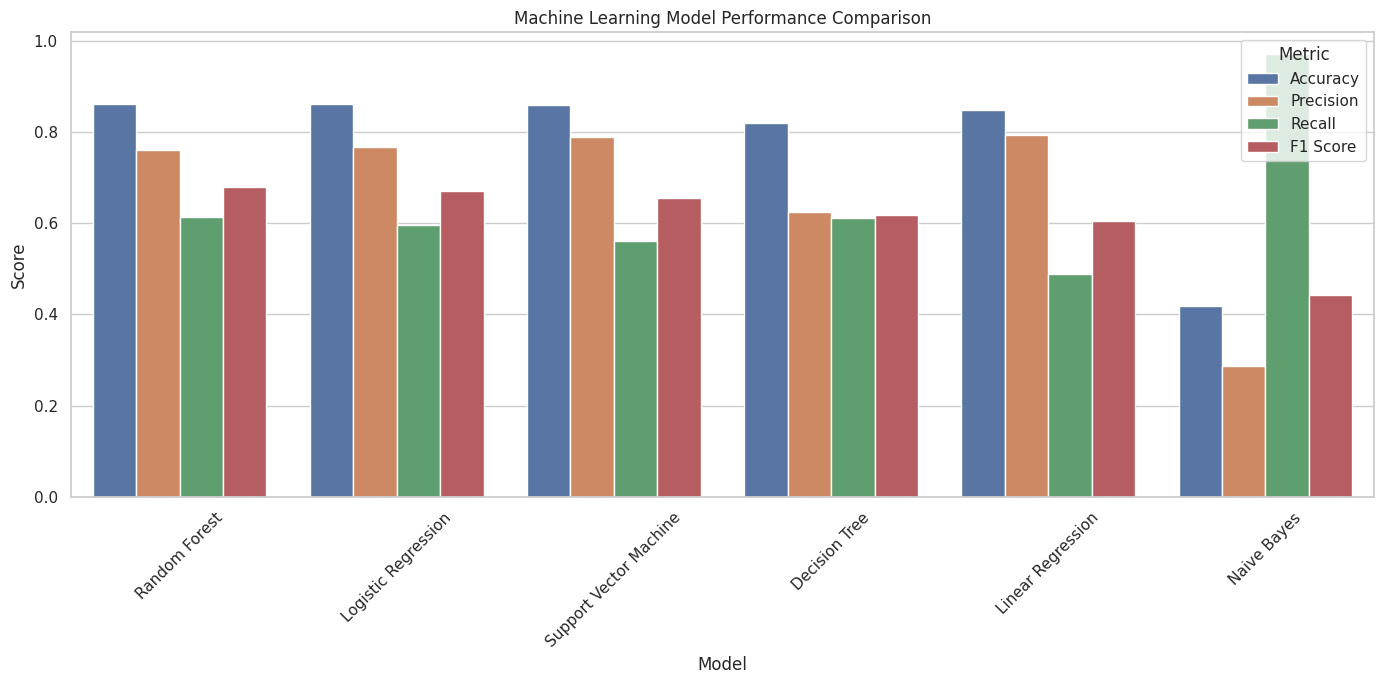

In [35]:
# MODEL PERFORMANCE VISUALIZATION
"""
Compare different evaluation metrics visually.
Metrics:
• Accuracy
• Precision
• Recall
• F1 Score
"""

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plot_data = (
    final_comparison
    .reset_index()
    .rename(
        columns={ "index":"Model" }
    )
)

plot_data = plot_data.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14,7))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title( "Machine Learning Model Performance Comparison" )
plt.xlabel( "Model" )
plt.ylabel( "Score" )
plt.xticks( rotation=45 )
plt.legend( title="Metric" )
plt.tight_layout()
plt.show()

In [36]:
# SELECT BEST PERFORMING MODEL
"""
Automatically select the model with the highest F1 Score.
"""

best_model_name = (
    final_comparison
    .index[0]
)

best_model = trained_models[
    best_model_name
]

best_results = final_comparison.loc[
    best_model_name
]

print("="*60)
print("🏆 BEST MODEL")
print("="*60)
print( "Model:", best_model_name )
print( "\nPerformance Metrics\n" )
print( "Accuracy :", round(best_results["Accuracy"], 4) )
print( "Precision:", round(best_results["Precision"], 4) )
print( "Recall   :", round(best_results["Recall"], 4) )
print( "F1 Score :", round(best_results["F1 Score"], 4) )
print( "Training Time:", round(best_results["Training Time (s)"], 4), "seconds")

🏆 BEST MODEL
Model: Random Forest

Performance Metrics

Accuracy : 0.8619
Precision: 0.7604
Recall   : 0.6146
F1 Score : 0.6798
Training Time: 15.1859 seconds


In [37]:
# SAVE FINAL MODEL
"""
Save the trained best-performing model and preprocessing pipeline for future predictions.
"""

import joblib

joblib.dump(
    {
        "model": best_model,
        "preprocessor": preprocessor,
        "feature_names": feature_names
    },
    "adult_income_classifier.pkl"
)

print( "Best model, preprocessing pipeline and feature names saved successfully!" )

Best model, preprocessing pipeline and feature names saved successfully!


# **Project Conclusion**

• This project developed machine learning models
  to predict whether an individual's income exceeds
  $50,000 using census information.

• Several supervised learning algorithms were
  evaluated including Logistic Regression, SVM,
  Naive Bayes, Decision Tree, Random Forest, and
  Linear Regression.

• Random Forest and tree-based approaches generally
  performed well because they can capture complex
  relationships between demographic features.

• Linear models provided a useful baseline but were
  limited in handling nonlinear relationships.

• K-Means clustering was evaluated separately using
  ARI and NMI because it does not use class labels
  during training.

---

### **Final Result:**
Based on the evaluation metrics, the model that achieved the strongest overall balance between precision, recall, and F1-score is: **Random Forest**.

---